In [104]:
import numpy as np
import matplotlib.pyplot as plt
import scipy as scp
nx = 64
x_period = 2
Lx = 2*np.pi * x_period
ny = 64
Ly = np.pi
nz = 64
z_period = 5
Lz = 2*np.pi * z_period
x = np.linspace(0, Lx, nx, endpoint=False)
y = np.linspace(0, Ly, ny)
z = np.linspace(0, Lz, nz, endpoint=False)

x_phase = 0.4
z_phase = 1.7
X, Y, Z = np.ix_(x, y, z)
p = np.cos(X + x_phase) * np.cos(Y) * np.cos(Z + z_phase)

In [105]:
rhs = -3 * p

In [106]:
rhsxzhat = np.fft.fftn(rhs, axes=(0, 2))
rhshat = scp.fft.dct(rhsxzhat, type=1, axis=1)

In [107]:
dx = Lx / nx
dy = Ly / (ny - 1)
dz = Lz / nz

kx = 2 * np.pi * np.fft.fftfreq(nx, dx)
ky = np.pi * np.arange(ny) / Ly
kz = 2 * np.pi * np.fft.fftfreq(nz, dz)

In [108]:
K2 = -(kx[:, None, None]**2 + ky[None, :, None]**2 + kz[None, None, :]**2)
K2[0, 0, 0] = 1.0
phat = rhshat / K2
phat[0, 0, 0] = 0.0

In [109]:
interxz = scp.fft.idct(phat, type=1, axis=1) 
p_solver = np.fft.ifftn(interxz, axes=(0, 2))

In [110]:
np.abs(p_solver.imag).sum()

np.float64(7.855274412254763e-12)

In [111]:
p_ana = p - p.mean()
p_num = p_solver.real - p_solver.real.mean()
np.sqrt(np.mean((p_num - p_ana) ** 2)) / np.sqrt(np.mean(p_ana**2))


np.float64(7.565622815967334e-16)

In [112]:
np.abs(p_num - p_ana).max() / np.abs(p_ana).max()

np.float64(1.2774053958377094e-15)

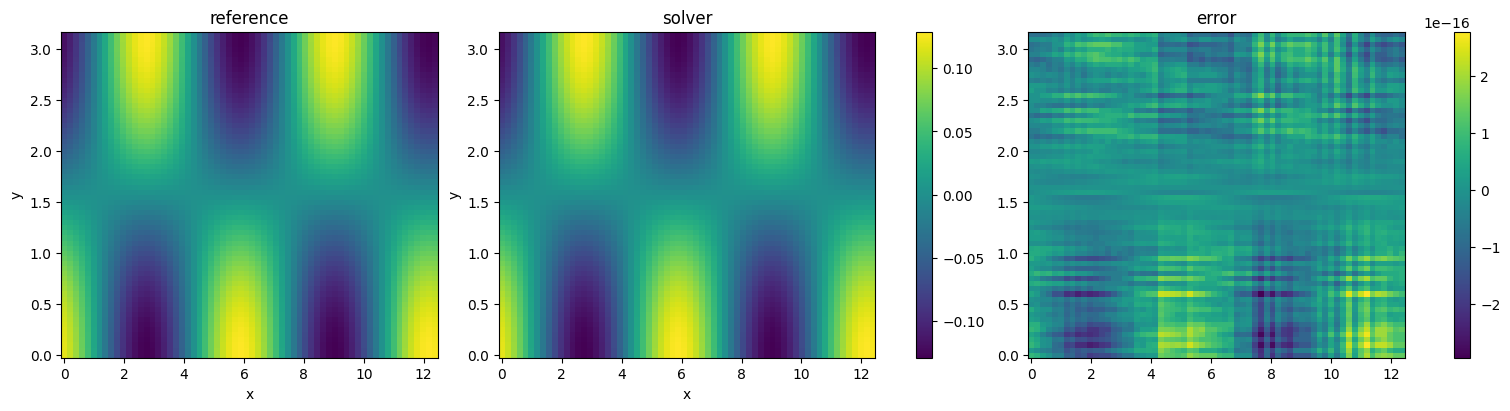

In [113]:
import matplotlib.pyplot as plt

kslice = nz // 2
ref = p_ana[:, :, kslice]
num = p_num[:, :, kslice]

vmin, vmax = ref.min(), ref.max()
fig, ax = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)

for a, f, t in zip(ax[:2], (ref, num), ("reference", "solver")):
    im = a.pcolormesh(x, y, f.T, vmin=vmin, vmax=vmax, shading="auto")
    a.set_title(t)
    a.set_xlabel("x"); a.set_ylabel("y")
fig.colorbar(im, ax=ax[:2])

err = ax[2].pcolormesh(x, y, (num - ref).T, shading="auto")
ax[2].set_title("error")
fig.colorbar(err, ax=ax[2])
plt.show()

In [114]:
rhsxzhat = np.fft.fftn(rhs, axes=(0, 2))
rhshat = scp.fft.dct(rhsxzhat, axis=1)
kprimex = (alpha * np.sin(kx * dx) + (b / 2) * np.sin(2 * kx * dx)) / (1 + 2 * alpha * cos(kx * dx)) * 1/dx
K2 = -(kx[:, None, None]**2 + ky[None, :, None]**2 + kz[None, None, :]**2)
K2[0, 0, 0] = 1.0
phat = rhshat / K2
phat[0, 0, 0] = 0.0
interxz = scp.fft.idct(phat, axis=1) 
p_solver = np.fft.ifftn(interxz, axes=(0, 2))

NameError: name 'alpha' is not defined

In [ ]:
np.abs(p_solver.imag).sum()

In [ ]:
p_ana = p - p.mean()
p_num = p_solver.real - p_solver.real.mean()
np.sqrt(np.mean((p_num - p_ana) ** 2)) / np.sqrt(np.mean(p_ana**2))
